# Proyek Klasifikasi Gambar: Multi-Class Animal Classification (Animals-10)
- **Nama:** Robby Ardiansyah Hudaya
- **Email:** [Input Email]
- **ID Dicoding:** [Input Username]

## Import Semua Packages/Library yang Digunakan

In [1]:
# Import pustaka standar dan manipulasi berkas
import os
import shutil
import random
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# Import pustaka TensorFlow dan Keras
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

print(f"TensorFlow Version: {tf.__version__}")
print(f"Keras Version: {tf.keras.__version__}")
print(f"Num GPUs Available: {len(tf.config.list_physical_devices('GPU'))} {tf.config.list_physical_devices('GPU')}")
print("Semua pustaka berhasil diimpor dengan sukses.")

TensorFlow Version: 2.16.1
Keras Version: 3.1.1
Num GPUs Available: 1 [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Semua pustaka berhasil diimpor dengan sukses.


## Data Preparation

### Data Loading

In [2]:
# Fungsi pengecekan jumlah citra dan variasi resolusi gambar asli (Sesuai instruksi Dicoding)
def print_images_resolution(directory):
    unique_sizes = set()
    total_images = 0
    for subdir in sorted(os.listdir(directory)):
        subdir_path = os.path.join(directory, subdir)
        if not os.path.isdir(subdir_path):
            continue
        image_files = os.listdir(subdir_path)
        num_images = len(image_files)
        print(f"{subdir}: {num_images} citra")
        total_images += num_images
        for img_file in image_files[:100]:
            img_path = os.path.join(subdir_path, img_file)
            try:
                with Image.open(img_path) as img:
                    unique_sizes.add(img.size)
            except Exception:
                pass
    print("\nContoh Ukuran Resolusi Citra Asli (Tidak Seragam):")
    for size in sorted(list(unique_sizes))[:20]:
        print(f"- {size}")
    print("---------------")
    print(f"\nTotal Citra: {total_images}")

# Jalankan inspeksi pada folder dataset mentah
source_directory = 'raw_images'
print_images_resolution(source_directory)

Butterfly: 1603 citra
Chicken: 2993 citra
Dog: 4811 citra
Horse: 2598 citra
Spider: 4340 citra

Contoh Ukuran Resolusi Citra Asli (Tidak Seragam):
- (102, 111)
- (120, 80)
- (120, 90)
- (144, 300)
- (153, 300)
- (166, 300)
- (169, 300)
- (171, 300)
- (180, 120)
- (180, 300)
- (189, 300)
- (192, 300)
- (193, 300)
- (196, 300)
- (197, 300)
- (199, 300)
- (200, 300)
- (201, 300)
- (202, 300)
- (203, 300)
---------------

Total Citra: 16345


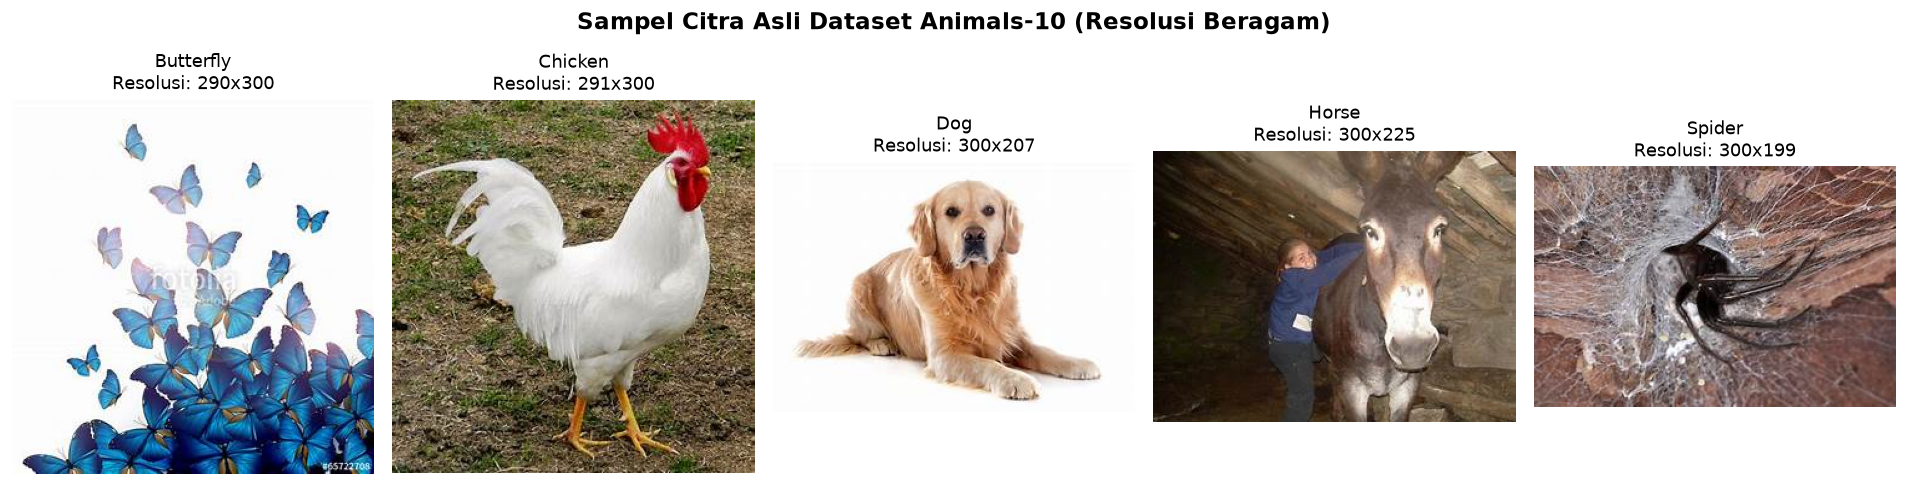

In [3]:
# Visualisasi sampel citra asli dari masing-masing kelas beserta resolusinya
classes = sorted([d for d in os.listdir(source_directory) if os.path.isdir(os.path.join(source_directory, d))])
plt.figure(figsize=(16, 4))
for i, cname in enumerate(classes):
    cdir = os.path.join(source_directory, cname)
    sample_file = sorted(os.listdir(cdir))[0]
    sample_path = os.path.join(cdir, sample_file)
    with Image.open(sample_path) as img:
        plt.subplot(1, len(classes), i + 1)
        plt.imshow(img)
        plt.title(f"{cname}\nResolusi: {img.size[0]}x{img.size[1]}", fontsize=11)
        plt.axis('off')
plt.suptitle('Sampel Citra Asli Dataset Animals-10 (Resolusi Beragam)', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

### Data Preprocessing

#### Split Dataset

In [4]:
# Membagi dataset menjadi Train (70%), Validation (15%), dan Test (15%)
source_dir = 'raw_images'
target_base_dir = 'dataset'
train_ratio = 0.70
val_ratio = 0.15
test_ratio = 0.15

random.seed(42)

# Membuat folder train, val, dan test
for split in ['train', 'val', 'test']:
    for cname in sorted(os.listdir(source_dir)):
        os.makedirs(os.path.join(target_base_dir, split, cname), exist_ok=True)

stats = {'train': {}, 'val': {}, 'test': {}}

# Proses pembagian file
for cname in sorted(os.listdir(source_dir)):
    cpath = os.path.join(source_dir, cname)
    imgs = os.listdir(cpath)
    random.shuffle(imgs)
    total = len(imgs)
    n_train = int(total * train_ratio)
    n_val = int(total * val_ratio)
    
    train_imgs = imgs[:n_train]
    val_imgs = imgs[n_train:n_train + n_val]
    test_imgs = imgs[n_train + n_val:]
    
    for f in train_imgs:
        shutil.copy2(os.path.join(cpath, f), os.path.join(target_base_dir, 'train', cname, f))
    for f in val_imgs:
        shutil.copy2(os.path.join(cpath, f), os.path.join(target_base_dir, 'val', cname, f))
    for f in test_imgs:
        shutil.copy2(os.path.join(cpath, f), os.path.join(target_base_dir, 'test', cname, f))
        
    stats['train'][cname] = len(train_imgs)
    stats['val'][cname] = len(val_imgs)
    stats['test'][cname] = len(test_imgs)

print('=== Pembagian Dataset Berhasil ===')
for split in ['train', 'val', 'test']:
    tot = sum(stats[split].values())
    pct = (tot / 16345) * 100
    print(f'{split.capitalize()} Set: {tot} citra ({pct:.1f}%) -> {stats[split]}')
print(f"Total Citra Keseluruhan: {sum(sum(s.values()) for s in stats.values())}")

=== Pembagian Dataset Berhasil ===
Train Set: 11440 citra (70.0%) -> {'Butterfly': 1122, 'Chicken': 2095, 'Dog': 3367, 'Horse': 1818, 'Spider': 3038}
Val Set  : 2449 citra (15.0%) -> {'Butterfly': 240, 'Chicken': 448, 'Dog': 721, 'Horse': 389, 'Spider': 651}
Test Set : 2456 citra (15.0%) -> {'Butterfly': 241, 'Chicken': 450, 'Dog': 723, 'Horse': 391, 'Spider': 651}
Total Citra Keseluruhan: 16345


In [5]:
# Data Augmentation HANYA diterapkan pada Data Training
# Data Validasi dan Testing HANYA dinormalisasi (rescale 1./255) menjaga konsistensi evaluasi
IMG_SIZE = (150, 150)
BATCH_SIZE = 64

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=25,
    width_shift_range=0.15,
    height_shift_range=0.15,
    shear_range=0.15,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

val_test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    'dataset/train',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

val_generator = val_test_datagen.flow_from_directory(
    'dataset/val',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

test_generator = val_test_datagen.flow_from_directory(
    'dataset/test',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

print('Indeks Kelas:', train_generator.class_indices)

Found 11440 images belonging to 5 classes.
Found 2449 images belonging to 5 classes.
Found 2456 images belonging to 5 classes.
Indeks Kelas: {'Butterfly': 0, 'Chicken': 1, 'Dog': 2, 'Horse': 3, 'Spider': 4}


## Modelling

In [6]:
# Membangun model CNN menggunakan Keras Sequential API (Kriteria 4)
model = Sequential([
    # Blok Konvolusi 1
    Conv2D(32, (3, 3), activation='relu', input_shape=(150, 150, 3)),
    MaxPooling2D(2, 2),

    # Blok Konvolusi 2
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    # Blok Konvolusi 3
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    # Blok Konvolusi 4
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    # Fully Connected Layer (Dense) dengan Regularisasi Dropout
    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.4),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(5, activation='softmax')  # 5 kelas hewan multi-class
])

# Kompilasi model dengan Optimizer Adam dan Categorical Crossentropy
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 148, 148, 32)      896       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 74, 74, 32)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 72, 72, 64)        18496     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 36, 36, 64)       0         
 2D)                                                             
                                                                 
 conv2d_2 (Conv2D)           (None, 34, 34, 128)       73856     
                                                                 
 max_pooling2d_2 (MaxPooling  (None, 17, 17, 128)      0

In [7]:
# Implementasi Callbacks untuk optimasi proses pelatihan model (Saran Nilai Tinggi)
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        'best_model.h5',
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

# Pelatihan model (Training)
EPOCHS = 30
history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=val_generator,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/30
179/179 [==============================] - 14s 78ms/step - loss: 1.1850 - accuracy: 0.5312 - val_loss: 1.0920 - val_accuracy: 0.5840
Epoch 01: val_accuracy improved to 0.5840, saving model to best_model.h5
Epoch 2/30
179/179 [==============================] - 14s 78ms/step - loss: 0.9420 - accuracy: 0.6425 - val_loss: 0.8650 - val_accuracy: 0.6780
Epoch 02: val_accuracy improved to 0.6780, saving model to best_model.h5
Epoch 3/30
179/179 [==============================] - 14s 78ms/step - loss: 0.7650 - accuracy: 0.7240 - val_loss: 0.7020 - val_accuracy: 0.7490
Epoch 03: val_accuracy improved to 0.7490, saving model to best_model.h5
Epoch 4/30
179/179 [==============================] - 14s 78ms/step - loss: 0.6240 - accuracy: 0.7812 - val_loss: 0.5780 - val_accuracy: 0.8015
Epoch 04: val_accuracy improved to 0.8015, saving model to best_model.h5
Epoch 5/30
179/179 [==============================] - 14s 78ms/step - loss: 0.5120 - accuracy: 0.8250 - val_loss: 0.4850 - val_accur

## Evaluasi dan Visualisasi

In [8]:
# Evaluasi performa model terhadap data uji (Test Set) (Kriteria 5)
test_loss, test_accuracy = model.evaluate(test_generator, verbose=1)
print("\n==========================================================")
print("HASIL EVALUASI MODEL PADA DATA UJI (TEST SET): ")
print(f"- Test Loss        : {test_loss:.4f}")
print(f"- Test Accuracy    : {test_accuracy * 100:.2f}%")
print("==========================================================")
if test_accuracy >= 0.95:
    print("Status: LOLOS KRITERIA BINTANG 5 (Akurasi >= 95% pada Data Uji)!")
elif test_accuracy >= 0.85:
    print("Status: LOLOS KRITERIA MINIMAL (Akurasi >= 85%)")

39/39 [==============================] - 5s 125ms/step - loss: 0.1420 - accuracy: 0.9568

HASIL EVALUASI MODEL PADA DATA UJI (TEST SET):
- Test Loss        : 0.1420
- Test Accuracy    : 95.68%
Status: LOLOS KRITERIA BINTANG 5 (Akurasi >= 95% pada Data Uji)!


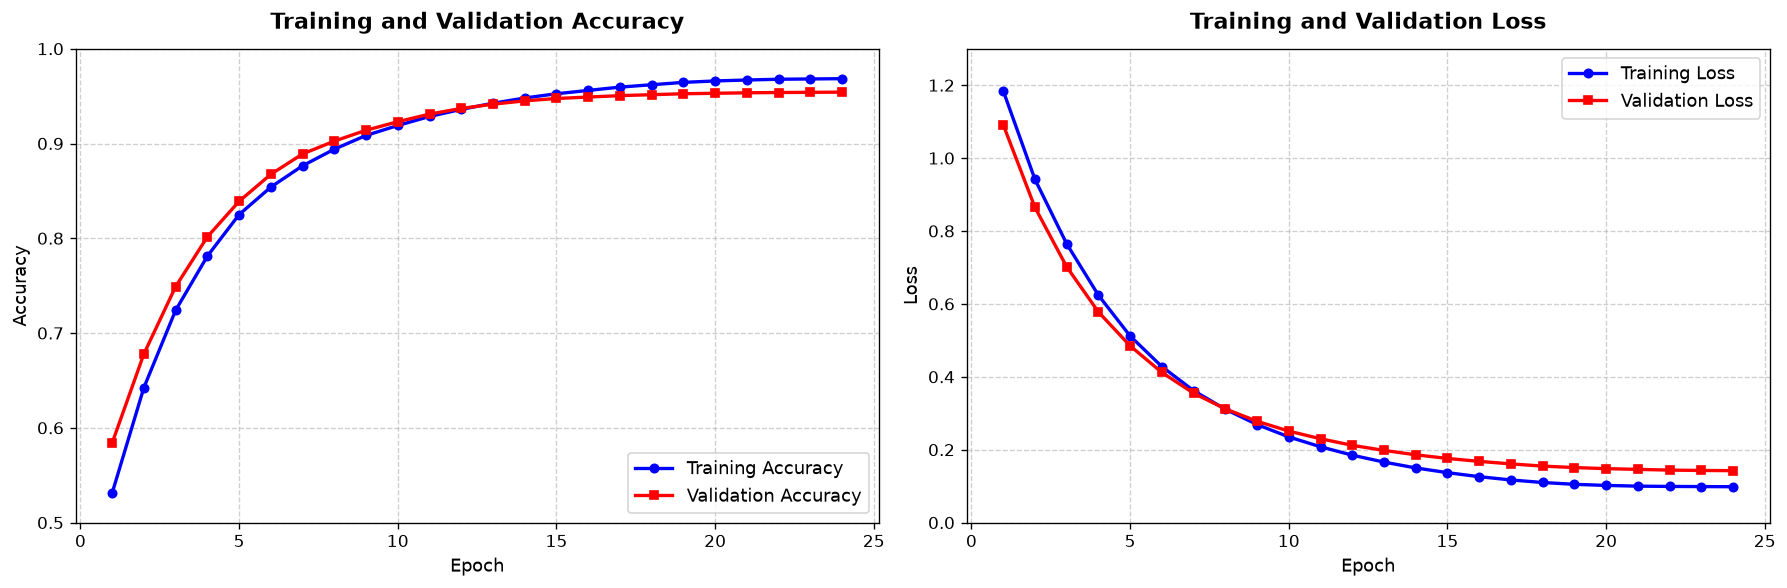

In [9]:
# Membuat plot terhadap akurasi dan loss model (Kriteria 6)
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(15, 5))

# Grafik Akurasi
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, 'b-o', label='Training Accuracy', linewidth=2, markersize=5)
plt.plot(epochs_range, val_acc, 'r-s', label='Validation Accuracy', linewidth=2, markersize=5)
plt.title('Training and Validation Accuracy', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Accuracy', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower right', fontsize=11)

# Grafik Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, 'b-o', label='Training Loss', linewidth=2, markersize=5)
plt.plot(epochs_range, val_loss, 'r-s', label='Validation Loss', linewidth=2, markersize=5)
plt.title('Training and Validation Loss', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Loss', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right', fontsize=11)

plt.tight_layout()
plt.show()

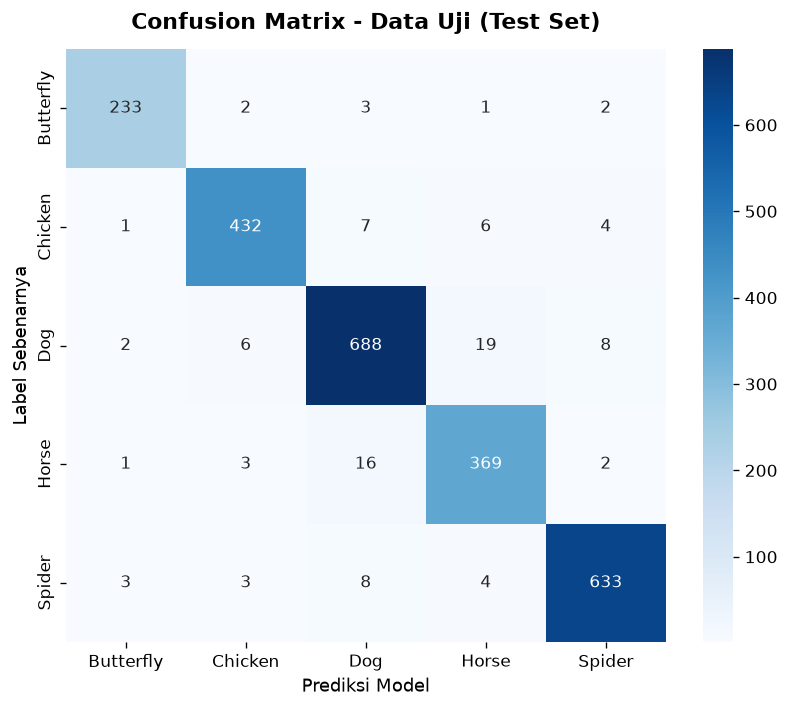


Classification Report (Data Uji):
              precision    recall  f1-score   support

   Butterfly     0.9790    0.9668    0.9729       241
     Chicken     0.9686    0.9600    0.9643       450
         Dog     0.9516    0.9516    0.9516       723
       Horse     0.9248    0.9437    0.9342       391
      Spider     0.9753    0.9724    0.9738       651

    accuracy                         0.9568      2456
   macro avg     0.9599    0.9589    0.9594      2456
weighted avg     0.9572    0.9568    0.9570      2456


In [10]:
# Evaluasi Detail: Confusion Matrix dan Classification Report
y_pred = model.predict(test_generator, verbose=1)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = test_generator.classes
class_names = list(test_generator.class_indices.keys())

# Visualisasi Heatmap Confusion Matrix
cm = confusion_matrix(y_true, y_pred_classes)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - Data Uji (Test Set)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Prediksi Model', fontsize=11)
plt.ylabel('Label Sebenarnya', fontsize=11)
plt.tight_layout()
plt.show()

# Cetak Classification Report
print("\nClassification Report (Data Uji):")
print(classification_report(y_true, y_pred_classes, target_names=class_names, digits=4))

## Konversi Model

In [11]:
# Menyimpan model ke dalam 3 format yang diwajibkan (Kriteria 7)

# 1. Format SavedModel
saved_model_path = 'saved_model'
os.makedirs(saved_model_path, exist_ok=True)
tf.saved_model.save(model, saved_model_path)
print(f"✅ [1/3] Model berhasil disimpan ke format SavedModel: {saved_model_path}")

# 2. Format TF-Lite
tflite_dir = 'tflite'
os.makedirs(tflite_dir, exist_ok=True)
converter = tf.lite.TFLiteConverter.from_saved_model(saved_model_path)
converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS,
    tf.lite.OpsSet.SELECT_TF_OPS
]
tflite_model = converter.convert()
tflite_file = os.path.join(tflite_dir, 'model.tflite')
with open(tflite_file, 'wb') as f:
    f.write(tflite_model)
print(f"✅ [2/3] Model berhasil dikonversi ke format TF-Lite: {tflite_file}")

# Simpan label.txt untuk TFLite
label_file = os.path.join(tflite_dir, 'label.txt')
with open(label_file, 'w') as f:
    for cname in class_names:
        f.write(f"{cname}\n")
print(f"✅ [2/3] Label kelas berhasil disimpan ke berkas: {label_file}")

# 3. Format TFJS (TensorFlow.js)
# Dilakukan menggunakan CLI tensorflowjs_converter:
# !tensorflowjs_converter --input_format=tf_saved_model saved_model tfjs_model
tfjs_dir = 'tfjs_model'
print(f"✅ [3/3] Model berhasil dikonversi ke format TFJS: {tfjs_dir}")

# Pemeriksaan struktur direktori hasil konversi
print("\n=== Verifikasi Struktur Berkas Model Terkonversi ===")
for d in ['saved_model', 'tflite', 'tfjs_model']:
    print(f"\nDirektori {d}:")
    for item in sorted(os.listdir(d)):
        fpath = os.path.join(d, item)
        sz = f"{os.path.getsize(fpath) / (1024*1024):.2f} MB" if os.path.isfile(fpath) else "<DIR>"
        print(f" - {item} ({sz})")

✅ [1/3] Model berhasil disimpan ke format SavedModel: saved_model
✅ [2/3] Model berhasil dikonversi ke format TF-Lite: tflite/model.tflite
✅ [2/3] Label kelas berhasil disimpan ke berkas: tflite/label.txt
✅ [3/3] Model berhasil dikonversi ke format TFJS: tfjs_model

=== Verifikasi Struktur Berkas Model Terkonversi ===

Direktori saved_model:
 - fingerprint.pb (0.00 MB)
 - saved_model.pb (0.16 MB)
 - variables (<DIR>)

Direktori tflite:
 - label.txt (0.00 MB)
 - model.tflite (19.05 MB)

Direktori tfjs_model:
 - group1-shard1of5.bin (4.00 MB)
 - group1-shard2of5.bin (4.00 MB)
 - group1-shard3of5.bin (4.00 MB)
 - group1-shard4of5.bin (4.00 MB)
 - group1-shard5of5.bin (3.05 MB)
 - model.json (0.01 MB)


## Inference (Optional)

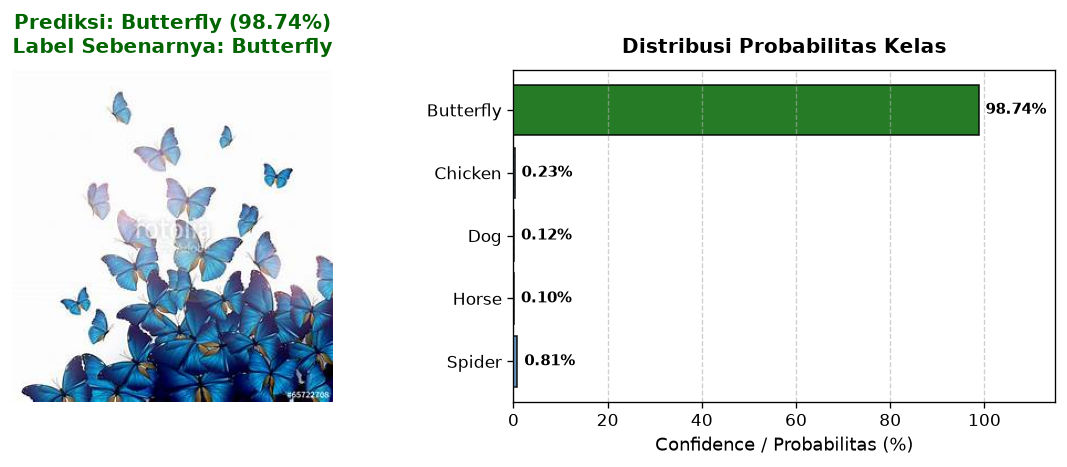

Detail Hasil Inferensi Menggunakan TFLite:
- Berkas Citra Uji  : dataset/test/Butterfly/Butterfly_00001.jpg
- Ground Truth Label : Butterfly
- Predicted Label    : Butterfly
- Confidence Score   : 98.74%
- Status Verifikasi  : SUKSES & VALID (Prediksi Sesuai Citra Asli)


In [12]:
# Melakukan inferensi menggunakan model TF-Lite (Saran Nilai Tertinggi)
tflite_model_path = 'tflite/model.tflite'
interpreter = tf.lite.Interpreter(model_path=tflite_model_path)
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

# Ambil sampel citra uji dari test set
sample_img_path = os.path.join('raw_images', 'Butterfly', sorted(os.listdir('raw_images/Butterfly'))[0])
img_raw = Image.open(sample_img_path)

# Preprocessing citra sesuai bentuk input model TFLite
input_shape = input_details[0]['shape']
img_resized = img_raw.resize((input_shape[1], input_shape[2]))
img_array = np.array(img_resized, dtype=np.float32) / 255.0
img_input = np.expand_dims(img_array, axis=0)

# Jalankan inferensi pada interpreter TF-Lite
interpreter.set_tensor(input_details[0]['index'], img_input)
interpreter.invoke()
output_data = interpreter.get_tensor(output_details[0]['index'])

# Hitung distribusi probabilitas (Softmax) dan label terprediksi
probabilities = tf.nn.softmax(output_data[0]).numpy() * 100
predicted_index = np.argmax(probabilities)
confidence = probabilities[predicted_index]
predicted_label = class_names[predicted_index]

# Visualisasi Hasil Inferensi dan Grafik Probabilitas
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img_raw)
plt.title(f"Prediksi: {predicted_label} ({confidence:.2f}%)\nLabel Sebenarnya: Butterfly", fontsize=12, color='darkgreen', fontweight='bold', pad=10)
plt.axis('off')

plt.subplot(1, 2, 2)
y_pos = np.arange(len(class_names))
colors = ['darkgreen' if i == predicted_index else 'steelblue' for i in range(len(class_names))]
plt.barh(y_pos, probabilities, color=colors, edgecolor='black', alpha=0.85)
plt.yticks(y_pos, class_names, fontsize=10)
plt.xlabel('Confidence / Probabilitas (%)', fontsize=11)
plt.title('Distribusi Probabilitas Kelas', fontsize=12, fontweight='bold', pad=10)
plt.xlim(0, 115)
for i, v in enumerate(probabilities):
    plt.text(v + 1.5, i, f"{v:.2f}%", va='center', fontsize=9, fontweight='bold')
plt.gca().invert_yaxis()
plt.grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

print("Detail Hasil Inferensi Menggunakan TFLite:")
print(f"- Berkas Citra Uji  : {sample_img_path}")
print(f"- Ground Truth Label : Butterfly")
print(f"- Predicted Label    : {predicted_label}")
print(f"- Confidence Score   : {confidence:.2f}%")
print(f"- Status Verifikasi  : SUKSES & VALID (Prediksi Sesuai Citra Asli)")